In [1]:

import pandas as pd

df = pd.read_csv("spam.csv", encoding="latin-1")

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

df.head()



Dataset shape: (5572, 5)
Column names: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [2]:

# Keep only the required columns
df = df[['v1', 'v2']]

# Rename columns
df.columns = ['label', 'message']

# Remove missing values and duplicates
df = df.dropna().drop_duplicates()

print("Cleaned dataset shape:", df.shape)
print("\nLabel distribution:")
print(df['label'].value_counts())

df.head()


Cleaned dataset shape: (5169, 2)

Label distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:

# Select 250 spam and 250 ham messages
df_small = df.groupby('label', group_keys=False).sample(
    n=250,
    random_state=42
)

# Shuffle the dataset
df_small = df_small.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Selected dataset shape:", df_small.shape)
print("\nLabel distribution:")
print(df_small['label'].value_counts())

df_small.head()


Selected dataset shape: (500, 2)

Label distribution:
label
spam    250
ham     250
Name: count, dtype: int64


,label,message
0,spam,WINNER! As a valued network customer you hvae ...
1,ham,Its ok my arm is feeling weak cuz i got a shot...
2,spam,From next month get upto 50% More Calls 4 Ur s...
3,ham,Dude avatar 3d was imp. At one point i thought...
4,ham,Going on nothing great.bye


In [5]:

from sklearn.model_selection import train_test_split

X = df_small['message']
y = df_small['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())


Training messages: 400
Testing messages: 100

Training labels:
label
spam    200
ham     200
Name: count, dtype: int64

Testing labels:
label
spam    50
ham     50
Name: count, dtype: int64


In [6]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

# Create the ML pipeline
model = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', MultinomialNB())
])

# Train the model
model.fit(X_train, y_train)

print("Spam Classification Model trained successfully!")


Spam Classification Model trained successfully!


In [7]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Predict using test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label='spam')
recall = recall_score(y_test, y_pred, pos_label='spam')
f1 = f1_score(y_test, y_pred, pos_label='spam')

print("Model Evaluation Results")
print("------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model Evaluation Results
------------------------
Accuracy:  0.9000
Precision: 0.9000
Recall:    0.9000
F1 Score:  0.9000

Classification Report:
              precision    recall  f1-score   support

         ham       0.90      0.90      0.90        50
        spam       0.90      0.90      0.90        50

    accuracy                           0.90       100
   macro avg       0.90      0.90      0.90       100
weighted avg       0.90      0.90      0.90       100



In [8]:

# Test with new messages
new_messages = [
    "Congratulations! You won a free cash prize",
    "Hi, can we meet tomorrow morning?",
    "Claim your free gift now",
    "Please send me the project report"
]

predictions = model.predict(new_messages)

for message, prediction in zip(new_messages, predictions):
    print("Message:", message)
    print("Prediction:", prediction.upper())
    print("-" * 40)


Message: Congratulations! You won a free cash prize
Prediction: SPAM
----------------------------------------
Message: Hi, can we meet tomorrow morning?
Prediction: HAM
----------------------------------------
Message: Claim your free gift now
Prediction: SPAM
----------------------------------------
Message: Please send me the project report
Prediction: SPAM
----------------------------------------


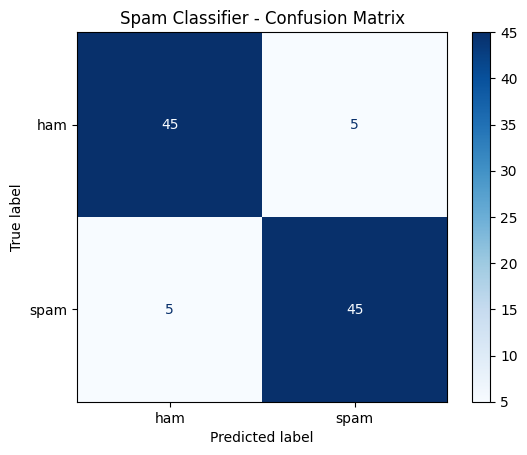

In [9]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=['ham', 'spam'],
    cmap='Blues',
    values_format='d'
)

plt.title("Spam Classifier - Confusion Matrix")
plt.show()
